# Time Series - Clusters

A `TimeSeriesCluster` holds series of the **same variable from different sites**, like a network of weather stations or rain gauges. Unlike a `TimeSeriesCollection`, which accepts miscellaneous data, a cluster can compare its series against each other: how correlated the sites are, and how one site can fill the gaps of another.

This tutorial builds a synthetic network of five temperature stations in two sub-regions:

| Station | Sub-region | Range | Gaps |
|---|---|---|---|
| `S1` | west | full year | 1 large (30d) |
| `S2` | west | full year | none |
| `S3` | west | full year | none |
| `S4` | east | Mar-Dec (shorter) | none |
| `S5` | east | full year | 1 small (3d) |

Covered here:

- Loading the stations into a `TemperatureSeriesCluster`
- Viewing data availability and all series together
- Correlation between stations via `get_correlation()`
- Gap filling from other stations via `regionalize()`, comparing uniform and inverse-distance weights

```{seealso}
Check out the {doc}`Time Series - Collections <timeseries_07_collection>` tutorial first.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
import copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.datasets import TemperatureSeriesCluster
from plans.datasets.analyst import Bivar

# This avoids warnings related to uninstalled fonts
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

OUTPUT_DIR = Path("outputs/time-series-cluster")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: ./{OUTPUT_DIR}")

rng = np.random.default_rng(seed=7)  # ensure reproducibility

Outputs will be saved to: ./outputs\time-series-cluster


## Build a synthetic station network

Each station gets the same cycle, a weather anomaly common to the whole region, a weather anomaly of its own sub-region, and some local shocks. The anomalies have memory (an autoregressive process), so warm or cold spells last for some days. Stations in the same sub-region share more signal, so they should correlate more.

In [2]:
n = 365
t = np.arange(n)

def make_anomaly(phi, sd):
    # autoregressive anomaly: a[t] = phi * a[t-1] + shock
    a = np.zeros(n)
    e = rng.normal(loc=0, scale=sd, size=n)
    for i in range(1, n):
        a[i] = phi * a[i - 1] + e[i]
    return a

cycle = 18 + 4 * np.sin(2 * np.pi * (t - 100) / 365)
anomaly_region = make_anomaly(phi=0.8, sd=1.0)
anomaly_subregion = {
    "west": make_anomaly(phi=0.8, sd=1.2),
    "east": make_anomaly(phi=0.8, sd=1.2),
}

# stations: sub-region and coordinates (km)
stations = pd.DataFrame({
    "Name": ["S1", "S2", "S3", "S4", "S5"],
    "Subregion": ["west", "west", "west", "east", "east"],
    "X": [0, 2, 1, 10, 11],
    "Y": [0, 1, 3, 2, 0],
})

dates = pd.date_range(start="2021-01-01", periods=n, freq="D")
dc_series = {}
for _, row in stations.iterrows():
    dc_series[row["Name"]] = (
        cycle
        + anomaly_region
        + anomaly_subregion[row["Subregion"]]
        + rng.normal(loc=0, scale=0.8, size=n)
    )

Lets look at where the stations are:

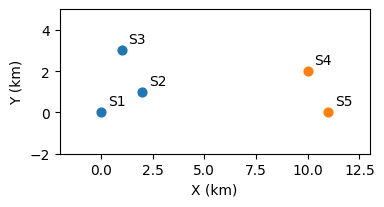

In [3]:
fig, ax = plt.subplots(figsize=(4, 3))
colors = {"west": "tab:blue", "east": "tab:orange"}
for _, row in stations.iterrows():
    ax.scatter(row["X"], row["Y"], color=colors[row["Subregion"]], s=40)
    ax.annotate(row["Name"], (row["X"], row["Y"]), xytext=(5, 5), textcoords="offset points")
ax.set_xlim(-2, 13)
ax.set_ylim(-2, 5)
ax.set_aspect("equal")
ax.set_xlabel("X (km)")
ax.set_ylabel("Y (km)")
plt.show()

Now add the gaps. Before removing the values of the large gap in `S1`, keep them as the **truth**, so we can later check how well the gap was filled:

In [4]:
# large gap in S1 -- keep the truth
GAP = slice(150, 180)
truth = dc_series["S1"][GAP].copy()
dc_series["S1"][GAP] = np.nan

# small gap in S5
dc_series["S5"][200:203] = np.nan

# save files -- S4 starts later
ls_files = []
for name, values in dc_series.items():
    df = pd.DataFrame({"datetime": dates, "T": values})
    if name == "S4":
        df = df.iloc[60:]
    file = OUTPUT_DIR / f"{name}.csv"
    df.to_csv(file, sep=";", index=False)
    ls_files.append(str(file))
print(ls_files)

['outputs\\time-series-cluster\\S1.csv', 'outputs\\time-series-cluster\\S2.csv', 'outputs\\time-series-cluster\\S3.csv', 'outputs\\time-series-cluster\\S4.csv', 'outputs\\time-series-cluster\\S5.csv']


## Load into a Time Series Cluster

Like a collection, a cluster is loaded from an info table. The `X` and `Y` columns are the station coordinates, used later for inverse-distance weights. Here we use `TemperatureSeriesCluster`, a cluster ready for temperature series:

In [5]:
info = pd.DataFrame({
    "Name": stations["Name"],
    "Alias": stations["Name"],
    "File": ls_files,
    "VarField": "T",
    "DtField": "datetime",
    "Units": "C",
    "X": stations["X"],
    "Y": stations["Y"],
    "Code": stations["Name"],
    "Source": "synthetic",
    "Description": "daily air temperature, " + stations["Subregion"] + " sub-region",
    "Color": "tab:red",
})
info_file = OUTPUT_DIR / "info.csv"
info.to_csv(info_file, sep=";", index=False)

tsc = TemperatureSeriesCluster(name="Network")
tsc.load_data(table_file=info_file)
tsc.catalog[["name", "x", "y", "start", "end", "variable_min", "variable_max"]]

,name,x,y,start,end,variable_min,variable_max
0,S1,0,0,2021-01-01,2021-12-31,7.014798,27.477313
1,S2,2,1,2021-01-01,2021-12-31,8.057301,27.454874
2,S3,1,3,2021-01-01,2021-12-31,8.387260,26.842874
3,S4,10,2,2021-03-02,2021-12-31,8.225353,26.716260
4,S5,11,0,2021-01-01,2021-12-31,7.162614,25.622818


## Data availability

The default `.view()` is inherited from the collection: the Gantt chart of each series epochs, the overlapping data across series, and the series prevalence. Note the gap in `S1` and the late start of `S4`:

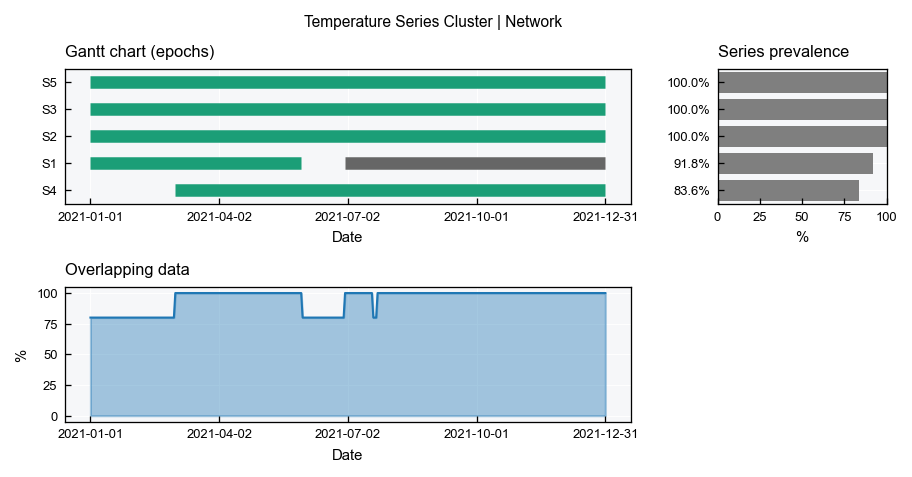

In [6]:
tsc.view()

## All series together

Since all series are the same variable, they can share the same axes. The `series` layout mirrors the single `TimeSeries` view, overlaying every station: the series, their histograms (with common bins) and their CDFs, with dashed lines for the means:

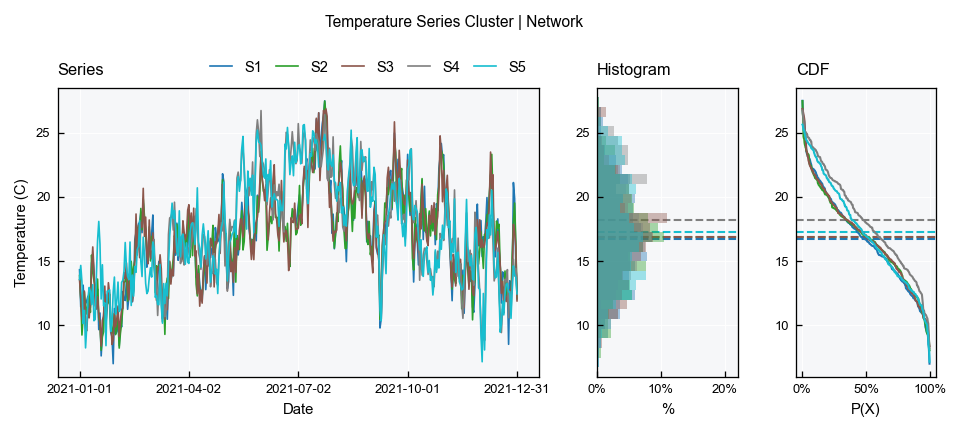

In [7]:
tsc.view_specs["layout"] = "series"
tsc.view()

The cycle dominates, but the two sub-regions drift apart during warm and cold spells. Note also that `S4` has a higher mean: its record starts in March, missing the coldest months. Comparing statistics between sites requires a common period.

For the series only, use the `series-simple` layout:

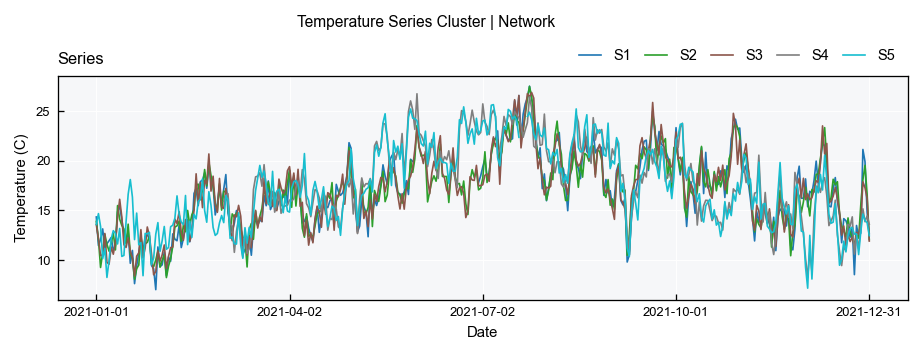

In [8]:
tsc.view_specs["layout"] = "series-simple"
tsc.view()

## Correlation between stations

The `.get_correlation()` method computes the correlation matrix between all stations, using only the time steps where both have data. Pairs with fewer overlapping steps than `min_overlap` are set to `NaN`:

In [9]:
df_corr = tsc.get_correlation(method="pearson", min_overlap=30)
df_corr.round(3)

,S1,S2,S3,S4,S5
S1,1.000,0.952,0.952,0.644,0.690
S2,0.952,1.000,0.953,0.607,0.673
S3,0.952,0.953,1.000,0.617,0.685
S4,0.644,0.607,0.617,1.000,0.961
S5,0.690,0.673,0.685,0.961,1.000


Use the `correlation` layout to see it as a heatmap:

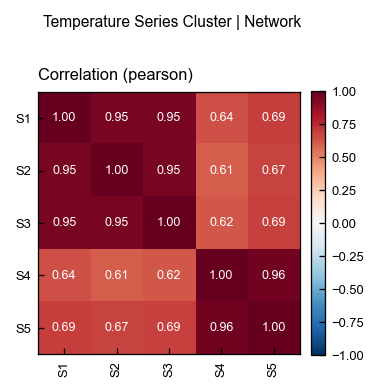

In [10]:
tsc.view_specs["layout"] = "correlation"
tsc.view()

The two sub-regions show up as two blocks: stations of the same sub-region correlate around 0.95, while stations of different sub-regions stay around 0.7. Spearman correlation is also available with `method="spearman"`.

```{note}
With a strong cycle, correlation is partly driven by the shared cycle itself. Even unrelated sites under the same climate correlate well.
```

## Filling gaps from other stations

The `.regionalize()` method fills the gaps of every station with a weighted average of the other stations, on the time steps where they have data. Observed values are never changed. Two weighting methods are available:

- `average`: all other stations get the same weight.
- `idw`: inverse distance weighting, closer stations get more weight.

Check the share of each station in the weights for `S1`:

In [11]:
df_weights = pd.DataFrame(
    {method: tsc.get_weights_by_name(name="S1", method=method) for method in ["average", "idw"]},
    index=["S2", "S3", "S4", "S5"],
)
df_weights = df_weights / df_weights.sum()
df_weights.round(2)

,average,idw
S2,0.25,0.47
S3,0.25,0.33
S4,0.25,0.10
S5,0.25,0.10


Since `.regionalize()` changes the data in place, lets run each method on a copy of the cluster:

In [12]:
dc_clusters = {}
for method in ["average", "idw"]:
    dc_clusters[method] = copy.deepcopy(tsc)
    dc_clusters[method].regionalize(method=method)

The gap in `S1` is now closed:

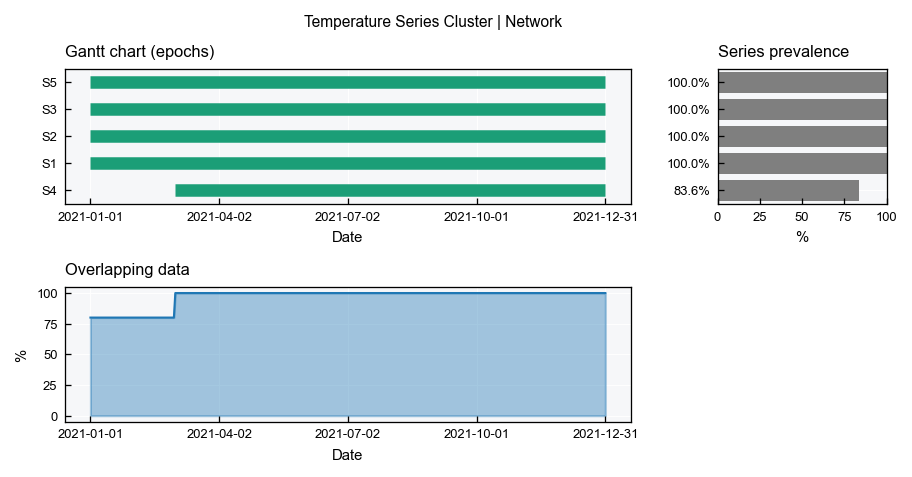

In [13]:
tsc_idw = dc_clusters["idw"]
tsc_idw.view_specs["layout"] = "full"
tsc_idw.view()

### How good is the filling?

Since we kept the truth, we can compare the filled values against it using the `Bivar` metrics:

In [14]:
gap_dates = dates[GAP]
dc_filled = {}
for method, cluster in dc_clusters.items():
    ts = cluster.collection["S1"]
    s = ts.data.set_index(ts.dtfield)[ts.varfield]
    dc_filled[method] = s.loc[gap_dates].values

df_metrics = pd.DataFrame(
    {method: Bivar.get_metrics(observed=truth, predicted=filled) for method, filled in dc_filled.items()}
).T
df_metrics[["RMSE", "MAE", "Bias", "R2"]]

,RMSE,MAE,Bias,R2
average,1.952558,1.547067,7.487313,0.022263
idw,1.040685,0.824099,2.649993,0.722251


And see it on the gap window:

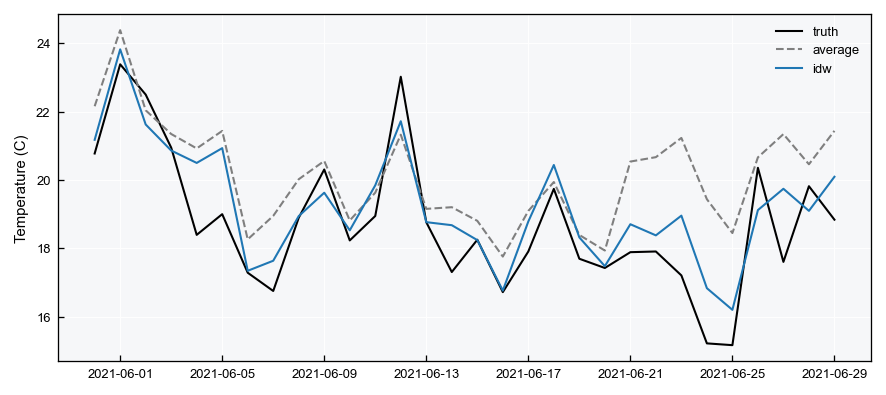

In [15]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(gap_dates, truth, color="black", label="truth")
ax.plot(gap_dates, dc_filled["average"], color="tab:gray", linestyle="--", label="average")
ax.plot(gap_dates, dc_filled["idw"], color="tab:blue", label="idw")
ax.set_ylabel("Temperature (C)")
ax.legend(frameon=False)
plt.show()

Inverse distance weighting follows the truth much closer, since it relies mostly on `S2` and `S3`, which share the west sub-region weather. The uniform average gives half of the weight to the east stations, which have their own weather.

```{warning}
`.regionalize()` takes the other stations values as they are. Stations with systematically different levels (e.g., temperature at different elevations) will bias the filling.
```

## Recap

- A `TimeSeriesCluster` holds same-variable series from different sites, loaded from an info table with station coordinates.
- The `series` and `correlation` layouts show the series together and the correlation between sites; the default layout shows data availability.
- `get_correlation()` compares sites on their overlapping time steps.
- `regionalize()` fills gaps from other sites, with uniform or inverse-distance weights.